<a href="https://colab.research.google.com/github/bejon23/Computational-Biology-and-BI-Eng/blob/main/Project_IDI044_of_Upwork_proposal_customizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ✍️ Upwork Proposal Customizer
**By Dr. Bejon Kumar Bhowmick | Biomedical AI & Data Engineering**

### Problem
Writing a fresh, personal proposal for every Upwork job takes a long time. Generic copy-paste proposals get ignored, and weak jobs waste Connects.

### Solution
This notebook reads a pasted job post, picks the best matching specialized profile, finds the client's key topics, deadline, budget and questions, and drafts a short proposal that answers them with a related portfolio link. It also checks quality and warns about risky jobs. You review and send manually.

### Output
Best-fit profile · Key topics · Client questions · Proposal draft · Quality score · Warnings · Tracker CSV

*Always edit the draft by hand before you send it.*

Setup

In [ ]:

!pip install -q openai

import re, html, os, uuid
import pandas as pd
from IPython.display import display, HTML
print("✅ Setup done")

✅ Setup done


Cell 2: Your profiles, proof and portfolio links
Edit this once. The proof lines must be true statements about your work.

In [ ]:

MY_NAME = "Dr. Bejon Kumar Bhowmick"
REPO_LINK = "https://github.com/bejon23/AI-Data-Eng-Architect-Bio-Health-Operational-/tree/main/"
LINKS = {
    "meta":  REPO_LINK + "gig7-medical-research/m1-meta-analysis-kit",
    "stats": REPO_LINK + "gig7-medical-research/m2-clinical-stats-report",
    "manu":  REPO_LINK + "gig7-medical-research/m3-thesis-to-manuscript",
    "main":  "https://github.com/bejon23/Computational-Biology-and-BI-Eng",  # ← your new safe public repo
}
PROFILES = {
  "thesis": {
    "label": "Thesis & Research Support",
    "keywords": ["meta-analysis","systematic review","prisma","forest plot","funnel plot","heterogeneity",
                 "thesis","dissertation","manuscript","journal","statistics","statistical","regression",
                 "survival","sample size","research proposal","table 1","spss","kaplan","cox"],
    "proof": "I have a PhD, postdoctoral and teaching experience, and I built a Python workflow that creates PRISMA flow, forest and funnel plots, heterogeneity checks and a written results paragraph.",
    "first_step": "I would start with a short review of your data and goal, then send a plan with a timeline and a first small result.",
    "question": "Which journal or supervisor guideline should the tables and figures follow?"},
  "bioinformatics": {
    "label": "Bioinformatics & Genomics",
    "keywords": ["rna-seq","rnaseq","genomics","bioinformatics","gene expression","differential expression",
                 "kegg","enrichment","multi-omics","biomarker","docking","autodock","variant","sequencing",
                 "ppi","single-cell","scrna","deg"],
    "proof": "I hold a PhD in Genomics and have built multi-omics, biomarker and docking pipelines that end in clear figures and a written methods and results section.",
    "first_step": "I would first check your data format and share a short plan with a timeline, then deliver a small first result so you can check quality early.",
    "question": "Which comparison or result matters most for your project?"},
  "ai_rag": {
    "label": "AI / LLM & RAG",
    "keywords": ["rag","llm","chatbot","langchain","embedding","vector","fastapi","nlp","clinical notes",
                 "gpt","openai","hugging face","transformer","fine-tune","semantic search"],
    "proof": "I built a production RAG system over 10,000+ biomedical papers that cut research synthesis time by about 70%, using hybrid search, reranking and a FastAPI deployment.",
    "first_step": "I would begin with a small prototype on a sample of your documents, so you see real answers before the full build.",
    "question": "How many documents do you have, and where are they stored?"},
  "comp_bio": {
    "label": "Computational Biology & Scientific Python",
    "keywords": ["computational biology","scientific coding","scientific computing","numerical modeling","numpy","scipy",
                 "systems biology","population modeling","ecology","biochemical kinetics","biochemistry","genetics",
                 "stochastic","simulation","reference solution","hidden tests","ai evaluation","benchmark","python"],
    "proof": "I hold a PhD in Genomics and write Python workflows (NumPy, SciPy, pandas) for scientific analysis, including statistical models and survival analysis, with the assumptions and parameters documented clearly.",
    "first_step": "I would begin with one sample problem worked end to end, covering the model, a Python reference solution and a check of the expected results, so you can judge my quality before scaling up.",
    "question": "Which subject area and difficulty level should I start with?"},
}
print("✅ Profiles loaded:", ", ".join(p["label"] for p in PROFILES.values()))

✅ Profiles loaded: Thesis & Research Support, Bioinformatics & Genomics, AI / LLM & RAG, Computational Biology & Scientific Python


Cell 3: Paste the job post here
This is the only cell you change for each new job.

In [ ]:

JOB_TITLE = "Meta-analysis for diabetes thesis (forest and funnel plots)"
JOB_POST = """I am a PhD student and need help with a meta-analysis for my diabetes thesis.
I have 18 studies in Excel. I need pooled effect sizes, a forest plot, a funnel plot and a heterogeneity check.
Deadline is 3 weeks. Budget is $300.
Please tell me which software you use and share previous work. Can you also explain the results so I can defend them in my viva?"""
print("Job loaded:", JOB_TITLE, "|", len(JOB_POST.split()), "words")

Job loaded: Meta-analysis for diabetes thesis (forest and funnel plots) | 68 words


Cell 4: Analyze the job
Finds the best profile, topics, budget, deadline, tools, client questions and warnings.

In [ ]:

def analyze_job(text):
    low = text.lower()
    scores = {k: sum(1 for w in p["keywords"] if w in low) for k, p in PROFILES.items()}
    cat = max(scores, key=scores.get)
    if scores[cat] == 0: cat = None
    kws = []
    if cat:
        kws = sorted([w for w in PROFILES[cat]["keywords"] if w in low], key=lambda w: -len(w))[:3]
    budget = re.findall(r"\$\s?([\d,]+(?:\.\d+)?)", text)
    dl = re.search(r"(\d+)\s*(day|week|month)s?", low)
    deadline = f"{dl.group(1)} {dl.group(2)}{'s' if int(dl.group(1)) > 1 else ''}" if dl else None
    tools = [t for t in ["python","spss","stata","excel","sas","revman","graphpad","langchain","fastapi","docker","pytorch","tensorflow"]
             if re.search(r"\b" + t + r"\b", low)]
    if re.search(r"\bR\b", text): tools.append("R")
    sents = [s.strip() for s in re.split(r"(?<=[.!?])\s+", text) if s.strip()]
    qs = [s for s in sents if s.endswith("?") or re.search(r"\b(please (tell|share|send|include|confirm)|let me know|which software)\b", s.lower())]
    flags = []
    checks = {r"whatsapp|telegram|outside upwork|off upwork": "Client wants to move outside Upwork. Do not agree.",
              r"free sample|free test|unpaid": "Unpaid test work is requested. Be careful.",
              r"write my thesis|ghostwrit|submit as my own|as my own work": "Possible academic-integrity problem. Offer analysis and guidance only.",
              r"100% (pass|accept)|guarantee (accept|publication)": "Client expects guaranteed results. Do not promise this."}
    for pat, msg in checks.items():
        if re.search(pat, low): flags.append(msg)
    tool_hits = [t for t in tools if t in ["spss","stata","sas","revman","graphpad"]]
    if tool_hits:
        flags.append("Client mentions " + "/".join(t.upper() for t in tool_hits) + ". Confirm you can deliver in that tool.")
    return {"category": cat, "scores": scores, "keywords": kws, "budget": budget, "deadline": deadline,
            "tools": tools, "questions": qs, "flags": flags}

info = analyze_job(JOB_POST)
print("Best-fit profile :", PROFILES[info["category"]]["label"] if info["category"] else "No clear match")
print("Match scores     :", info["scores"])
print("Key topics       :", info["keywords"])
print("Budget / Deadline:", info["budget"], "/", info["deadline"])
print("Tools mentioned  :", info["tools"])
print("Client questions :", info["questions"])
print("Warnings         :", info["flags"] if info["flags"] else "none")

Best-fit profile : Thesis & Research Support
Match scores     : {'thesis': 5, 'bioinformatics': 0, 'ai_rag': 0, 'comp_bio': 0}
Key topics       : ['meta-analysis', 'heterogeneity', 'forest plot']
Budget / Deadline: ['300'] / 3 weeks
Tools mentioned  : ['excel']
Client questions : ['Please tell me which software you use and share previous work.', 'Can you also explain the results so I can defend them in my viva?']
Warnings         : none


Cell 5: Build the proposal draft

In [ ]:

def pick_link(text, cat):
    low = text.lower()
    if cat != "thesis": return LINKS["main"]
    if re.search(r"manuscript|journal|cover letter|submission", low): return LINKS["manu"]
    if re.search(r"table 1|regression|survival|spss|kaplan|cox", low): return LINKS["stats"]
    return LINKS["meta"]

def join_words(items):
    if not items: return "this project"
    if len(items) == 1: return items[0]
    return ", ".join(items[:-1]) + " and " + items[-1]

def build_proposal(job_text, info):
    if not info["category"]:
        return "No clear match with your profiles. Read the job again before you apply."
    p = PROFILES[info["category"]]
    link = pick_link(job_text, info["category"])
    clause = f" within {info['deadline']}" if info["deadline"] else ""
    opening = f"You need {join_words(info['keywords'])} done correctly{clause}."
    answers = []
    for q in info["questions"]:
        ql = q.lower()
        if re.search(r"software|tool", ql):
            answers.append("I work in Python and R, with notebooks you can rerun, and I can export tables to Excel or Word.")
        if re.search(r"previous|portfolio|sample|example", ql):
            answers.append("A related sample is linked below.")
        if re.search(r"explain|defend|viva", ql):
            answers.append("I will also walk you through every result in simple words, so you can defend it.")
    seen = []
    for a in answers:
        if a not in seen: seen.append(a)
    answer_text = " ".join(seen[:3])
    parts = ["Hi,", opening, p["proof"], p["first_step"]]
    if answer_text: parts.append(answer_text)
    parts += [f"Related sample: {link}", p["question"], f"Best regards,\n{MY_NAME}"]
    return "\n\n".join(parts)

proposal = build_proposal(JOB_POST, info)
print(proposal)

Hi,

You need meta-analysis, heterogeneity and forest plot done correctly within 3 weeks.

I have a PhD, postdoctoral and teaching experience, and I built a Python workflow that creates PRISMA flow, forest and funnel plots, heterogeneity checks and a written results paragraph.

I would start with a short review of your data and goal, then send a plan with a timeline and a first small result.

I work in Python and R, with notebooks you can rerun, and I can export tables to Excel or Word. A related sample is linked below. I will also walk you through every result in simple words, so you can defend it.

Related sample: https://github.com/bejon23/AI-Data-Eng-Architect-Bio-Health-Operational-/tree/main/gig7-medical-research/m1-meta-analysis-kit

Which journal or supervisor guideline should the tables and figures follow?

Best regards,
Dr. Bejon Kumar Bhowmick


Cell 6: Quality check

In [ ]:

def check_proposal(text, info):
    body = text.split("Best regards")[0]
    words = len(body.split())
    bad = [b for b in ["i am excited","dear sir","dear sir/madam","i am the best","100% guarantee","i have read your job"] if b in body.lower()]
    results = [
        ("Length 90-170 words", 90 <= words <= 170, f"{words} words"),
        ("No generic phrases", not bad, ", ".join(bad) if bad else "ok"),
        ("Uses the client's topic words", all(k in body.lower() for k in info["keywords"][:2]), ", ".join(info["keywords"][:2])),
        ("Has a portfolio link", "http" in body, "link found" if "http" in body else "no link"),
        ("Ends with one question", "?" in body.strip().split("\n")[-1], "ok"),
    ]
    for name, ok, note in results:
        print("✅" if ok else "⚠", name, "-", note)
    for f in info["flags"]: print("🚩", f)
    print(f"\nScore: {sum(r[1] for r in results)}/{len(results)}")

check_proposal(proposal, info)

✅ Length 90-170 words - 122 words
✅ No generic phrases - ok
✅ Uses the client's topic words - meta-analysis, heterogeneity
✅ Has a portfolio link - link found
✅ Ends with one question - ok

Score: 5/5


Cell 7: Show it as a card

In [ ]:

def show_card(title, text, label):
    body = html.escape(text).replace("\n", "<br>")
    display(HTML(
        "<div style='border-left:6px solid #0f766e;background:#f7f7f9;color:#222;padding:14px;margin:10px 0;"
        "border-radius:8px;font-family:sans-serif;line-height:1.5'>"
        f"<div style='font-size:16px;font-weight:bold'>{html.escape(title)}</div>"
        f"<div style='font-size:12px;color:#555;margin-bottom:8px'>Use profile: {html.escape(label)}</div>{body}</div>"))

show_card(JOB_TITLE, proposal, PROFILES[info["category"]]["label"] if info["category"] else "none")

Cell 8: Optional AI polish
It uses your OPENAI_KEY secret if you have one. If not, it skips safely and keeps the template version.

In [ ]:

USE_AI = True
try:
    from google.colab import userdata
    key = userdata.get("OPENAI_KEY")
except Exception:
    key = None

if key and USE_AI:
    try:
        from openai import OpenAI
        client = OpenAI(api_key=key)
        prompt = ("Rewrite this Upwork proposal so it sounds natural and personal. Keep every fact, the link and the final question. "
                  "Do not add experience or claims. Under 150 words, no greetings like 'I am excited'.\n\n" + proposal)
        r = client.chat.completions.create(model="gpt-4o-mini", messages=[{"role": "user", "content": prompt}])
        polished = r.choices[0].message.content
        print(polished)
    except Exception as e:
        polished = proposal
        print("AI step skipped:", e)
else:
    polished = proposal
    print("ℹ No OpenAI key found. Using the template version (this is fine).")

ℹ No OpenAI key found. Using the template version (this is fine).


Cell 9: Save to the tracker

In [ ]:

final_text = polished
row = {"job_title": JOB_TITLE,
       "profile": PROFILES[info["category"]]["label"] if info["category"] else "none",
       "budget": ",".join(info["budget"]), "deadline": info["deadline"] or "",
       "status": "Not sent", "proposal": final_text}
tracker_file = "proposals_tracker.csv"
if os.path.exists(tracker_file):
    tr = pd.concat([pd.read_csv(tracker_file), pd.DataFrame([row])], ignore_index=True)
else:
    tr = pd.DataFrame([row])
tr.to_csv(tracker_file, index=False)
open("latest_proposal.txt", "w", encoding="utf-8").write(final_text)
print("✅ Saved:", tracker_file, "and latest_proposal.txt | proposals tracked:", len(tr))

try:
    from google.colab import files
    files.download("latest_proposal.txt")
except Exception as e:
    print("Download skipped:", e)

✅ Saved: proposals_tracker.csv and latest_proposal.txt | proposals tracked: 1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Cell 10 (optional): Save the tool to GitHub
This uploads only the example job and example proposal, with a README. It does not upload your real client jobs.

In [ ]:

import base64, requests, getpass
from google.colab import userdata

OWNER  = "bejon23"
REPO   = "AI-Data-Eng-Architect-Bio-Health-Operational-"
FOLDER = "tools/upwork-proposal-customizer"
BRANCH = "main"

README = """# Upwork Proposal Customizer

**Problem:** Writing a personal proposal for every Upwork job takes hours, and generic proposals get ignored.

**What it does**
- Reads a pasted job post
- Picks the best matching specialized profile
- Finds key topics, deadline, budget and client questions
- Drafts a short proposal with a related portfolio link
- Checks quality and warns about risky jobs

**Note:** example data only. Proposals are reviewed and sent manually.

Author: Dr. Bejon Kumar Bhowmick
"""
open("README.md", "w", encoding="utf-8").write(README)
open("sample_job.txt", "w", encoding="utf-8").write("SAMPLE JOB POST (example only)\n\n" + JOB_POST)
open("sample_proposal.txt", "w", encoding="utf-8").write("SAMPLE PROPOSAL (example only)\n\n" + final_text)
FILES = ["README.md", "sample_job.txt", "sample_proposal.txt"]

def token_ok(tok):
    r = requests.get("https://api.github.com/user",
                     headers={"Authorization": f"Bearer {tok}", "Accept": "application/vnd.github+json"})
    return r.status_code == 200, r.status_code

token = ""
try:
    token = "".join(userdata.get("GITHUB_TOKEN").split())
except Exception:
    print("ℹ No saved secret found.")
ok, status = token_ok(token) if token else (False, None)
if not ok:
    print("Paste a GitHub token below (it will stay hidden).")
    token = "".join(getpass.getpass("GitHub token: ").split())
    ok, status = token_ok(token)
print("Token status:", status)

if ok:
    for fname in FILES:
        url = f"https://api.github.com/repos/{OWNER}/{REPO}/contents/{FOLDER}/{fname}"
        headers = {"Authorization": f"Bearer {token}", "Accept": "application/vnd.github+json"}
        data = {"message": f"Add {fname}", "branch": BRANCH,
                "content": base64.b64encode(open(fname, "rb").read()).decode()}
        old = requests.get(url, headers=headers, params={"ref": BRANCH})
        if old.status_code == 200: data["sha"] = old.json()["sha"]
        r = requests.put(url, headers=headers, json=data)
        print(("✅" if r.status_code in (200, 201) else "❌"), fname, r.status_code)
    print(f"\nFolder link: https://github.com/{OWNER}/{REPO}/tree/{BRANCH}/{FOLDER}")
else:
    print("❌ Token not accepted. Create one with Contents: Read and write for this repo.")

Paste a GitHub token below (it will stay hidden).
GitHub token: ··········
Token status: 200
❌ README.md 403
❌ sample_job.txt 403
❌ sample_proposal.txt 403

Folder link: https://github.com/bejon23/AI-Data-Eng-Architect-Bio-Health-Operational-/tree/main/tools/upwork-proposal-customizer


Above link er share theke copy url korle ei downloaded files gulir github path pabo.

https://github.com/bejon23/AI-Data-Eng-Architect-Bio-Health-Operational-/tree/main/tools%2Fupwork-proposal-customizer

Or

Open the folder link in Chrome, in a private tab:
https://github.com/bejon23/AI-Data-Eng-Architect-Bio-Health-Operational-/tree/main/tools/upwork-proposal-customizer





Before I Send a Proposal

I edit the proposal by hand and add one detail that I specifically noticed in the job post. I make sure the client can see that my proposal is personalized, not fully automated.
I check my proof lines carefully and include only claims that are true. When I mention workflow examples, I describe them as demo projects and clearly label them as demos if the client asks.
I review any  warnings. If a client wants thesis work submitted as their own, I offer analysis and guidance only, not work intended to be misrepresented as the client's own.
I keep client data private. I never save real client names or job descriptions in a public GitHub repository. I keep my proposals_tracker.csv on my phone or in Google Drive.
I check every portfolio link by opening it in a private browser tab. If a portfolio folder does not exist yet, I use the notebook's fallback to my main repository link for Bioinformatics and AI jobs.

How I Use It for a New Job

I open the notebook and change only Cell 3, where I enter the job title and job description.
I select Runtime → Run all, skipping Cell 10 unless I want to update GitHub.
I copy the proposal from the card, edit it in my own words, and paste the final version into Upwork.

Upwork e  colab downloaded contents guli upload korbo manually or by colab codes. Option 1 :

Option A: Upload cell (easiest)
Run this as a new cell at the bottom of the Proposal Customizer notebook, after Cells 1 to 10 have run. It creates the folder tools/upwork-proposal-customizer and uploads a README, the sample job and the sample proposal. A hidden box asks for a GitHub token if the saved one fails.

In [ ]:

import base64, requests, getpass
from google.colab import userdata

OWNER  = "bejon23"
REPO   = "AI-Data-Eng-Architect-Bio-Health-Operational-"
FOLDER = "tools/upwork-proposal-customizer"
BRANCH = "main"

README = """# Upwork Proposal Customizer

**Problem:** Writing a personal proposal for every Upwork job takes hours, and generic proposals get ignored.

**What it does**
- Reads a pasted job post
- Picks the best matching specialized profile
- Finds key topics, deadline, budget and client questions
- Drafts a short proposal with a related portfolio link
- Checks quality and warns about risky jobs
- Makes a copy-and-paste pack for the Upwork form

**Note:** example data only. Proposals are reviewed and sent manually.

Author: Dr. Bejon Kumar Bhowmick
"""
open("README.md", "w", encoding="utf-8").write(README)
open("sample_job.txt", "w", encoding="utf-8").write("SAMPLE JOB POST (example only)\n\n" + JOB_POST)
open("sample_proposal.txt", "w", encoding="utf-8").write("SAMPLE PROPOSAL (example only)\n\n" + final_text)
FILES = ["README.md", "sample_job.txt", "sample_proposal.txt"]

def token_ok(tok):
    r = requests.get("https://api.github.com/user",
                     headers={"Authorization": f"Bearer {tok}", "Accept": "application/vnd.github+json"})
    return r.status_code == 200, r.status_code

token = ""
try:
    token = "".join(userdata.get("GITHUB_TOKEN").split())
except Exception:
    print("ℹ No saved secret found.")
ok, status = token_ok(token) if token else (False, None)
if not ok:
    print("Paste a GitHub token below (it will stay hidden).")
    token = "".join(getpass.getpass("GitHub token: ").split())
    ok, status = token_ok(token)
print("Token status:", status)

if ok:
    for fname in FILES:
        url = f"https://api.github.com/repos/{OWNER}/{REPO}/contents/{FOLDER}/{fname}"
        headers = {"Authorization": f"Bearer {token}", "Accept": "application/vnd.github+json"}
        data = {"message": f"Add {fname}", "branch": BRANCH,
                "content": base64.b64encode(open(fname, "rb").read()).decode()}
        old = requests.get(url, headers=headers, params={"ref": BRANCH})
        if old.status_code == 200: data["sha"] = old.json()["sha"]
        r = requests.put(url, headers=headers, json=data)
        print(("✅" if r.status_code in (200, 201) else "❌"), fname, r.status_code)
    print(f"\nFolder link: https://github.com/{OWNER}/{REPO}/tree/{BRANCH}/{FOLDER}")
else:
    print("❌ Token not accepted. Create one with Contents: Read and write for this repo.")

Paste a GitHub token below (it will stay hidden).
GitHub token: ··········
Token status: 200
❌ README.md 403
❌ sample_job.txt 403
❌ sample_proposal.txt 403

Folder link: https://github.com/bejon23/AI-Data-Eng-Architect-Bio-Health-Operational-/tree/main/tools/upwork-proposal-customizer


Github desk top login the open main repo then click then go to code then click tools then get Upworkproposal customization downloads folders visually uploaded in github

next
Save the notebook in this folder. In Colab, tap File → Save a copy in GitHub. Use the repo AI-Data-Eng-Architect-Bio-Health-Operational- and the path tools/upwork-proposal-customizer/Upwork_Proposal_Customizer.ipynb.

Before saving, make sure Cell 3 has only the example job proposal. This cell i will change for new jobs ( yitle, descriptions) later.


I will Delete my GitHub token from github personal token site (

 https://github.com/settings/personal-access-tokens/new) .  

In Chrome, go to GitHub → Settings → Developer settings → Personal access tokens, and delete the token I latest used to avoid hacking. Make a new one only when you need it.


Copy the folder link to use anywhere i want to show this tool, such as LinkedIn: https://github.com/bejon23/AI-Data-Eng-Architect-Bio-Health-Operational-/tree/main/tools/upwork-proposal-customizer

How to copy it?

Above mentioned  tools e click korle folder ( eg. Upwork-Proposal-Customizer) dekhte paben. Sei folder er share option click kore url copy korlei sobai ei folder structure peye jave github theke).

Your GitHub link shows more than the folder
Your repo is public. A client can tap any folder link, go up to the main repo page, and see everything: every gig folder, your other projects, and your profile. A single folder link cannot hide the rest.
Best fix: a small separate repo for this one project
Make a new public repo that contains only the meta-analysis project. The client sees only that.
Step 1: Create the repo (Chrome, Desktop site)
Go to github.com/new.
Repository name: meta-analysis-automation-kit
Choose Public.
Tick Add a README file.
Tap Create repository.
Step 2: Make a token for only this repo
Go to github.com/settings/personal-access-tokens/new.
Repository access: Only select repositories, then choose meta-analysis-automation-kit.
Permissions → Contents: Read and write. Expiration 7 days.
Generate and use the copy button.
Step 3: Run this cell in the Meta-Analysis notebook
Run it after Cells 1 to 7, so the images exist. A hidden box asks for the token.

Step 3: Run this cell in the Meta-Analysis notebook
Run it after Cells 1 to 7, so the images exist. A hidden box asks for the token.

Ei code ta code Cell e paste korte hobe

import base64, os, requests, getpass
from google.colab import userdata

OWNER  = "bejon23"
REPO   = "meta-analysis-automation-kit"
BRANCH = "main"
FILES  = ["forest_plot.png", "funnel_plot.png", "prisma_flow.png",
          "results_paragraph.txt", "meta_analysis_data.csv"]

README = """# Meta-Analysis Automation Kit

**Problem:** Doing a meta-analysis by hand is slow, and a small error in pooling or plots can cost a thesis chapter.

**What it does**
- PRISMA flow diagram
- Effect sizes (Hedges' g), fixed and random pooling
- Heterogeneity (Q, I², tau²) with automatic model choice
- Forest plot, funnel plot, Egger's test, leave-one-out check
- Auto-written results paragraph

**Data:** synthetic demo data. Replace it with your own study table.



![Forest plot](forest_plot.png)





![Funnel plot](funnel_plot.png)



Author: Dr. Bejon Kumar Bhowmick
"""
open("README.md", "w", encoding="utf-8").write(README)
FILES.append("README.md")

def token_ok(tok):
    r = requests.get("https://api.github.com/user",
                     headers={"Authorization": f"Bearer {tok}", "Accept": "application/vnd.github+json"})
    return r.status_code == 200, r.status_code

token = ""
try:
    token = "".join(userdata.get("GITHUB_TOKEN").split())
except Exception:
    print("ℹ No saved secret found.")
ok, status = token_ok(token) if token else (False, None)
if not ok:
    print("Paste a GitHub token for the NEW repo below (it will stay hidden).")
    token = "".join(getpass.getpass("GitHub token: ").split())
    ok, status = token_ok(token)
print("Token status:", status)

if ok:
    for fname in FILES:
        if not os.path.exists(fname):
            print(f"⚠ {fname} not found. Run the project cells first.")
            continue
        url = f"https://api.github.com/repos/{OWNER}/{REPO}/contents/{fname}"
        headers = {"Authorization": f"Bearer {token}", "Accept": "application/vnd.github+json"}
        data = {"message": f"Add {fname}", "branch": BRANCH,
                "content": base64.b64encode(open(fname, "rb").read()).decode()}
        old = requests.get(url, headers=headers, params={"ref": BRANCH})
        if old.status_code == 200:
            data["sha"] = old.json()["sha"]
        r = requests.put(url, headers=headers, json=data)
        print(("✅" if r.status_code in (200, 201) else "❌"), fname, r.status_code)
    print(f"\nShare this link: https://github.com/{OWNER}/{REPO}")
else:
    print("❌ Token not accepted. It needs Contents: Read and write for the new repo.")

More safety issues:


Other ways to share one project
Private repo + invite: make the repo Private, then Settings → Collaborators → Add people and enter the client's GitHub username. Only works if the client has GitHub.
Colab link: in Colab tap Share → Anyone with the link → Viewer, and send that link. It shows only that notebook. Anyone with the link can read it, so use demo data only.
Files in Upwork chat: send the PDF, images or ZIP directly in the Upwork message. Nothing else of yours is shown.
Secret Gist: at gist.github.com, a secret gist can be opened by link and doesn't appear on your profile, but it handles single files better than a project with images.
Remember
Even a separate public repo shows your GitHub username. Don't put your email, phone or any real client data in it.
Keep your chat and payment inside Upwork. Share links, not personal contact details.
Never put a real client's data or proposals in a public repo.
Delete the token after you finish.

Project ID1044

Problem Statement ( this into your Clb as the sample)


Title: Stochastic Gene Expression – Two-State Telegraph Model
Background
A gene switches between an inactive (OFF) and an active (ON) state. When ON, mRNA is produced at a constant rate and degraded. This is a classic telegraph model used in systems biology and single-cell transcriptomics.
Biological Model & Equations
States:
Gene: OFF ↔ ON
mRNA count: \( n = 0, 1, 2, \dots \)
Transition rates:
OFF → ON : \( k_{\text{on}} \)
ON → OFF : \( k_{\text{off}} \)
Transcription (only when ON): \( k_t \)
mRNA degradation: \( k_d \)
Deterministic mean mRNA level at steady state:
\[
\langle n \rangle = \frac{k_{\text{on}}}{k_{\text{on}} + k_{\text{off}}} \cdot \frac{k_t}{k_d}
\]

Assumptions
Single gene copy
No feedback or bursting beyond the two-state switch
Mass-action kinetics
Well-mixed cell (no spatial effects)
Parameters are constant

নিচে পুরো Colab প্রজেক্টটা সেল-বাই-সেল দিলাম।
প্রতিটা ব্লক আলাদা সেল হিসেবে পেস্ট করুন।


Cell0: Title and Problem Statement

# Stochastic Gene Expression – Two-State Telegraph Model

**Sample problem for AI-evaluation style computational biology tasks**

### Background
A gene switches between an inactive (OFF) and an active (ON) state.  
When ON, mRNA is produced at a constant rate and is degraded.  
This is the classic telegraph model used in systems biology and single-cell transcriptomics.

### Biological Model & Equations

**States**
- Gene: OFF ↔ ON
- mRNA count: n = 0, 1, 2, …

**Transition rates**
- OFF → ON : \( k_{on} \)
- ON → OFF : \( k_{off} \)
- Transcription (only when ON) : \( k_t \)
- mRNA degradation : \( k_d \)

**Steady-state mean mRNA**
\[
\langle n \rangle = \frac{k_{on}}{k_{on}+k_{off}} \cdot \frac{k_t}{k_d}
\]

### Assumptions
- Single gene copy
- No feedback
- Mass-action kinetics
- Well-mixed cell
- Constant parameters

### Task
Implement a function that simulates the stochastic telegraph model with the Gillespie algorithm and returns final mRNA counts, simulated mean, and theoretical mean.

Cell1: Setup

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from typing import Tuple

print(" Libraries loaded")

 Libraries loaded


Cell2 : ref solution (Gillespie algorithm)

In [ ]:

def simulate_telegraph(
    k_on: float,
    k_off: float,
    k_t: float,
    k_d: float,
    t_max: float,
    n_cells: int,
    seed: int = 42
) -> Tuple[np.ndarray, float, float]:
    """
    Stochastic simulation of the two-state telegraph model
    using the Gillespie (SSA) algorithm.

    Parameters
    ----------
    k_on, k_off, k_t, k_d : float
        Rate constants
    t_max : float
        Simulation time
    n_cells : int
        Number of independent cells
    seed : int
        Random seed for reproducibility

    Returns
    -------
    final_counts : np.ndarray, shape (n_cells,)
        Final mRNA count for each cell
    simulated_mean : float
        Mean of final_counts
    theoretical_mean : float
        Analytic steady-state mean
    """
    rng = np.random.default_rng(seed)
    final_counts = np.zeros(n_cells, dtype=int)

    for i in range(n_cells):
        # State: gene_on (0 or 1), mRNA count
        gene_on = 0          # start OFF
        n = 0
        t = 0.0

        while t < t_max:
            # Propensities
            a_on   = k_on  * (1 - gene_on)      # OFF → ON
            a_off  = k_off * gene_on            # ON → OFF
            a_tx   = k_t   * gene_on            # transcription
            a_deg  = k_d   * n                  # degradation

            a_total = a_on + a_off + a_tx + a_deg

            if a_total <= 0:
                break

            # Time to next reaction
            dt = rng.exponential(1.0 / a_total)
            t += dt
            if t > t_max:
                break

            # Choose reaction
            r = rng.random() * a_total
            if r < a_on:
                gene_on = 1
            elif r < a_on + a_off:
                gene_on = 0
            elif r < a_on + a_off + a_tx:
                n += 1
            else:
                n = max(0, n - 1)

        final_counts[i] = n

    simulated_mean = float(np.mean(final_counts))
    theoretical_mean = (k_on / (k_on + k_off)) * (k_t / k_d)

    return final_counts, simulated_mean, theoretical_mean


print("✅ Reference solution defined")

✅ Reference solution defined


Cell3: Run the main example ( acceptance test)

In [ ]:

# Parameters from the problem statement
params = dict(
    k_on=0.5,
    k_off=1.0,
    k_t=10.0,
    k_d=1.0,
    t_max=50.0,
    n_cells=2000,
    seed=42
)

counts, sim_mean, theo_mean = simulate_telegraph(**params)

print("Simulated mean :", round(sim_mean, 3))
print("Theoretical mean:", round(theo_mean, 3))
print("Absolute difference:", round(abs(sim_mean - theo_mean), 3))
print("Shape of counts:", counts.shape)
print("dtype:", counts.dtype)

# Acceptance criterion
assert abs(sim_mean - theo_mean) < 0.4, "Mean difference too large!"
assert counts.shape == (params["n_cells"],), "Wrong shape!"
print("\n✅ Acceptance test PASSED")

Simulated mean : 3.423
Theoretical mean: 3.333
Absolute difference: 0.09
Shape of counts: (2000,)
dtype: int64

✅ Acceptance test PASSED


Cell4; edge case test

In [ ]:

def run_edge_cases():
    print("Running edge-case tests...\n")

    # 1. Gene almost always OFF
    c, s, t = simulate_telegraph(k_on=0.01, k_off=5.0, k_t=10, k_d=1,
                                 t_max=40, n_cells=1000, seed=1)
    print(f"Almost OFF  → sim={s:.3f}, theo={t:.3f}, diff={abs(s-t):.3f}")

    # 2. Gene almost always ON
    c, s, t = simulate_telegraph(k_on=5.0, k_off=0.01, k_t=10, k_d=1,
                                 t_max=40, n_cells=1000, seed=2)
    print(f"Almost ON   → sim={s:.3f}, theo={t:.3f}, diff={abs(s-t):.3f}")

    # 3. Short time (not yet steady-state) – just check it runs
    c, s, t = simulate_telegraph(k_on=0.5, k_off=1.0, k_t=10, k_d=1,
                                 t_max=2.0, n_cells=500, seed=3)
    print(f"Short time  → sim={s:.3f}, theo={t:.3f} (expected larger difference)")

    # 4. Reproducibility
    c1, _, _ = simulate_telegraph(k_on=0.5, k_off=1, k_t=8, k_d=1,
                                  t_max=30, n_cells=300, seed=99)
    c2, _, _ = simulate_telegraph(k_on=0.5, k_off=1, k_t=8, k_d=1,
                                  t_max=30, n_cells=300, seed=99)
    assert np.array_equal(c1, c2), "Reproducibility failed!"
    print("Reproducibility → PASSED")

    print("\n✅ All edge-case tests completed")

run_edge_cases()

Running edge-case tests...

Almost OFF  → sim=0.033, theo=0.020, diff=0.013
Almost ON   → sim=9.925, theo=9.980, diff=0.055
Short time  → sim=2.190, theo=3.333 (expected larger difference)
Reproducibility → PASSED

✅ All edge-case tests completed


Cell5: Visualization

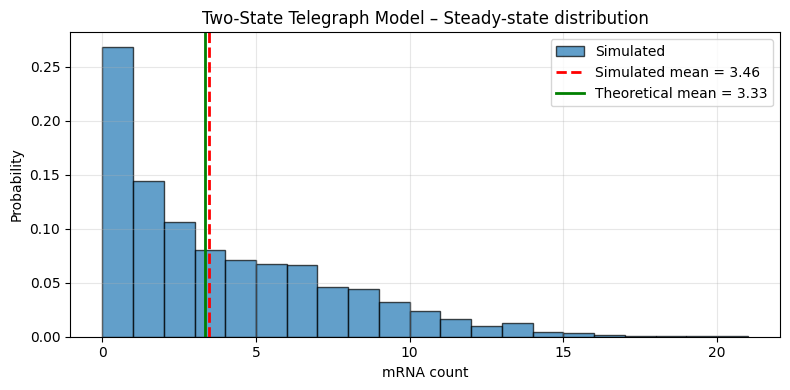

In [ ]:

counts, sim_mean, theo_mean = simulate_telegraph(
    k_on=0.5, k_off=1.0, k_t=10, k_d=1,
    t_max=50, n_cells=3000, seed=42
)

plt.figure(figsize=(8, 4))
plt.hist(counts, bins=range(0, counts.max()+2), density=True,
         alpha=0.7, edgecolor="black", label="Simulated")
plt.axvline(sim_mean, color="red", linestyle="--", linewidth=2,
            label=f"Simulated mean = {sim_mean:.2f}")
plt.axvline(theo_mean, color="green", linestyle="-", linewidth=2,
            label=f"Theoretical mean = {theo_mean:.2f}")
plt.xlabel("mRNA count")
plt.ylabel("Probability")
plt.title("Two-State Telegraph Model – Steady-state distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Cell 6 – Quick summary (for README / client)

In [ ]:

print("""
✅ Project complete

What this notebook demonstrates:
• Clear biological model + equations + assumptions
• Exact stochastic simulation (Gillespie SSA)
• Correct Python reference solution with typed inputs/outputs
• Acceptance test against analytic steady-state mean
• Edge-case handling and reproducibility
• Clean visualization of the result

This is the style of research-level computational biology
problem requested for AI evaluation benchmarks.
""")


✅ Project complete

What this notebook demonstrates:
• Clear biological model + equations + assumptions
• Exact stochastic simulation (Gillespie SSA)
• Correct Python reference solution with typed inputs/outputs
• Acceptance test against analytic steady-state mean
• Edge-case handling and reproducibility
• Clean visualization of the result

This is the style of research-level computational biology
problem requested for AI evaluation benchmarks.

